In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin

In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
df

,Carbon concentration,Silicon concentration,Manganese concentration,Sulphur concentration,Phosphorus concentration,Nickel concentration,Chromium concentration,Molybdenum concentration,Vanadium concentration,Copper concentration,...,Charpy temperature,Charpy impact toughness,Hardness,50 % FATT,Primary ferrite in microstructure,Ferrite with second phase,Acicular ferrite,Martensite,Ferrite with carbide aggreagate,Weld ID
0,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aht
3,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Baw
4,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,-48.0,100.0,NaN,NaN,32.0,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990/1991-0Bawch
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1647,0.100,0.35,0.90,0.008,0.016,0.60,8.6,0.98,0.18,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham-MAX35
1648,0.088,0.36,0.88,0.008,0.017,0.57,8.4,0.94,0.19,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham-MAX36
1649,0.090,0.34,0.89,0.008,0.016,0.17,8.2,0.94,0.02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham-MAX37
1650,0.092,0.35,0.90,0.008,0.016,0.54,8.4,0.97,0.17,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham-MAX38


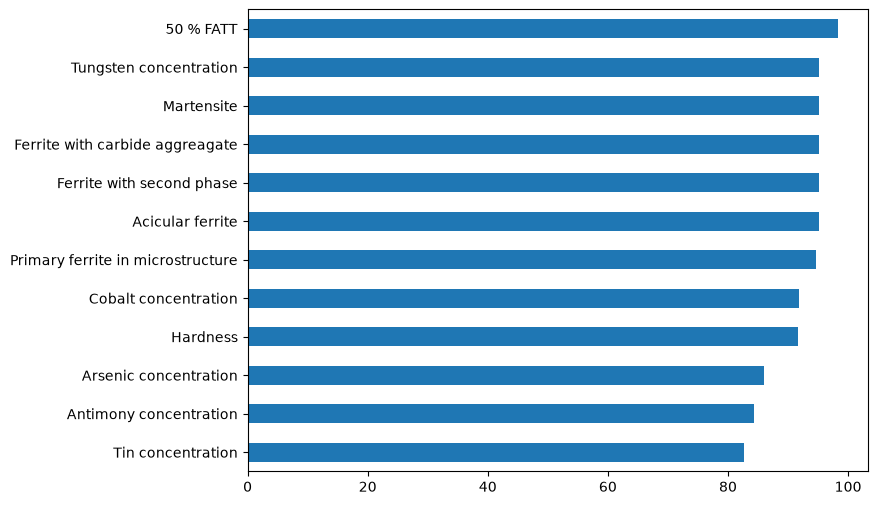

In [4]:
# Split des données
train_set, test_set = train_test_split(df, test_size = 0.2, random_state=42)

# Observation des valeurs manquantes
missing = train_set.isnull().mean().mul(100).sort_values(ascending=True)
missing[missing>80].plot(kind = "barh", figsize=(8,6))
plt.show()

# Suppression des colonnes à plus de 80% d'instance manquante
class DropMissingColumns(BaseEstimator, TransformerMixin):
    '''Supprime les colonnes dont le taux de manquants (calculé sur le train) dépasse un seuil.'''

    def __init__(self, threshold=0.8):
        self.threshold = threshold

    def fit(self, X, y=None):
        missing = X.isnull().mean()
        self.cols_to_drop_ = missing[missing >= self.threshold].index.tolist()
        return self

    def transform(self, X):
        return X.drop(columns=self.cols_to_drop_)

drop_columns = DropMissingColumns()
drop_columns.fit(train_set)
train_set = drop_columns.transform(train_set)
test_set = drop_columns.transform(test_set)

assert list(train_set.columns)== list(test_set.columns)

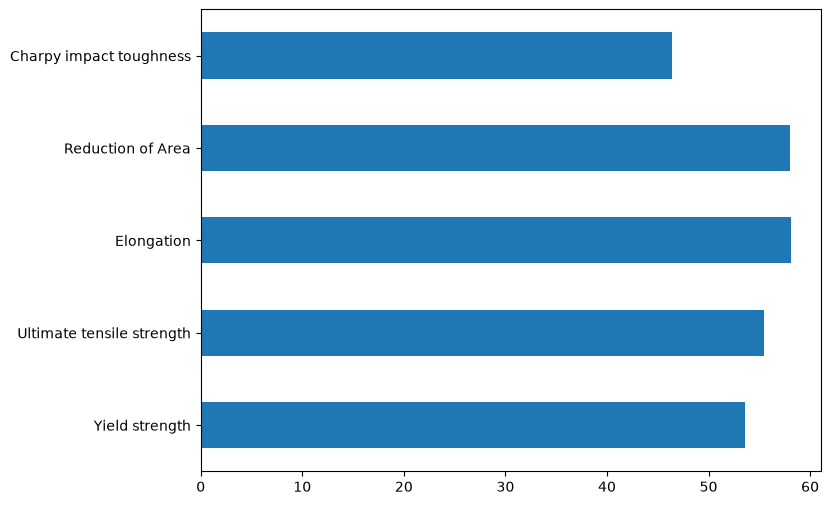

array([[<Axes: title={'center': 'Yield strength'}>,
        <Axes: title={'center': 'Ultimate tensile strength'}>],
       [<Axes: title={'center': 'Elongation'}>,
        <Axes: title={'center': 'Reduction of Area'}>],
       [<Axes: title={'center': 'Charpy impact toughness'}>, <Axes: >]],
      dtype=object)

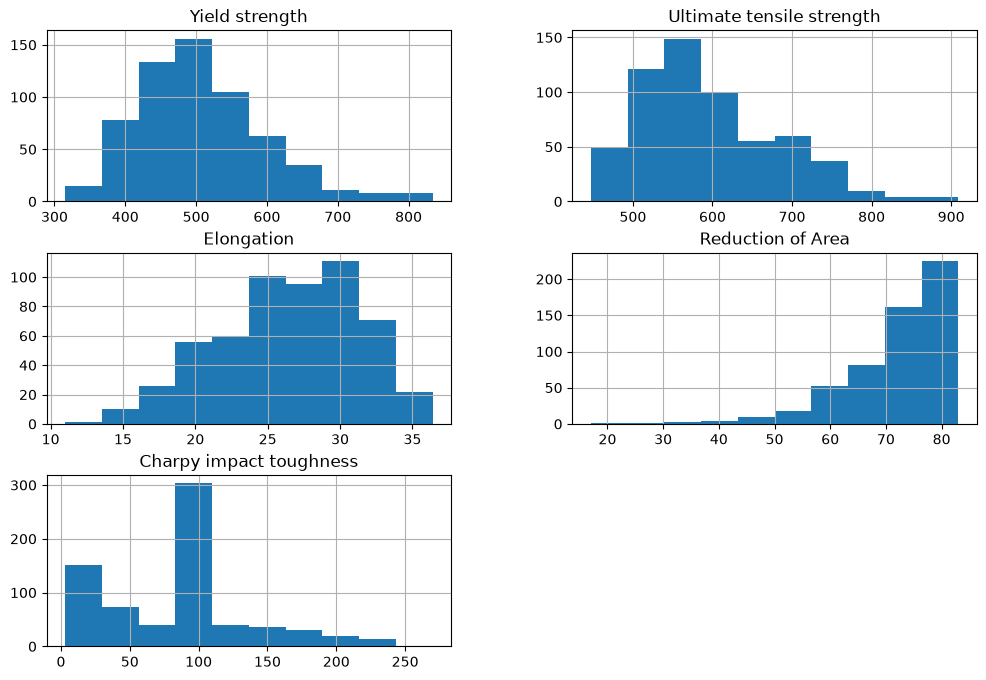

In [5]:
# Actualisation du tableau de correspondance 
mask_update = correspondance_between_names_units["Feature"].isin(train_set.columns)
correspondance_between_names_units = correspondance_between_names_units[mask_update]

# Extraction de la liste de target
mask_target = correspondance_between_names_units['Role'] == 'Quality indicator'
list_target = correspondance_between_names_units.loc[mask_target, "Feature"].to_list()

# Observation des valeurs manquantes
missing = train_set.isnull().mean().mul(100).sort_values(ascending=True)
missing[list_target].plot(kind = "barh", figsize=(8,6))
plt.show()

train_set[list_target].hist(figsize= (12,8))

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor   # ou le modèle que tu utilises
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin

class HotDeckImputer(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    def __init__(self, random_state=None):
        self.random_state = random_state

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = X.columns.to_numpy(dtype=object)
        self.n_features_in_ = X.shape[1]
        # p_k = n_k / n_obs pour chaque colonne (value_counts ignore les NaN)
        self.probas_ = {c: X[c].value_counts(normalize=True) for c in X.columns}
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        rng = np.random.default_rng(self.random_state)
        for c, p in self.probas_.items():
            missing = X[c].isnull()
            if missing.any():
                X.loc[missing, c] = rng.choice(p.index.to_numpy(), size=missing.sum(), p=p.to_numpy())
        return X
    
target = list_target[0]

train_t = train_set.dropna(subset=[target])
test_t = test_set.dropna(subset=[target])

X_train, y_train = train_t.drop(columns=list_target), train_t[target]
X_test, y_test = test_t.drop(columns=list_target), test_t[target]

id_col = "Weld ID"
num_cols = X_train.select_dtypes(include="number").columns.drop(id_col, errors="ignore")
cat_cols = X_train.select_dtypes(exclude="number").columns.drop(id_col, errors="ignore")

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", IterativeImputer(random_state=0, sample_posterior=True)),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
], verbose_feature_names_out=False)

full_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(random_state=0)),
])

param_grid = {
    "preprocess__num__imputer": [
        SimpleImputer(strategy="mean"),
        SimpleImputer(strategy="median"),
        IterativeImputer(random_state=0),
        IterativeImputer(random_state=0, sample_posterior=True),
    ],
    "preprocess__cat__imputer": [
        SimpleImputer(strategy="most_frequent"),
        SimpleImputer(strategy="constant", fill_value="missing"),
        HotDeckImputer(random_state=0),
        "passthrough",
    ],
}

grid = GridSearchCV(full_pipe, param_grid, cv=6,
                    scoring="neg_root_mean_squared_error", n_jobs=-1,
                    )

grid.fit(X_train, y_train)

res = pd.DataFrame(grid.cv_results_)[["param_preprocess__num__imputer",
                                      "param_preprocess__cat__imputer",
                                      "mean_test_score", "std_test_score"]]

res["RMSE"] = -res["mean_test_score"]
res.sort_values("RMSE")

,param_preprocess__num__imputer,param_preprocess__cat__imputer,mean_test_score,std_test_score,RMSE
1,SimpleImputer(strategy='median'),SimpleImputer(strategy='most_frequent'),-43.956599,4.264686,43.956599
9,SimpleImputer(strategy='median'),HotDeckImputer(random_state=0),-44.016026,4.230139,44.016026
13,SimpleImputer(strategy='median'),passthrough,-44.106882,4.250359,44.106882
5,SimpleImputer(strategy='median'),"SimpleImputer(fill_value='missing', strategy='...",-44.106882,4.250359,44.106882
8,SimpleImputer(),HotDeckImputer(random_state=0),-46.856171,3.002277,46.856171
0,SimpleImputer(),SimpleImputer(strategy='most_frequent'),-46.980909,2.995406,46.980909
12,SimpleImputer(),passthrough,-47.108272,3.090138,47.108272
4,SimpleImputer(),"SimpleImputer(fill_value='missing', strategy='...",-47.108272,3.090138,47.108272
2,IterativeImputer(random_state=0),SimpleImputer(strategy='most_frequent'),-48.325156,1.543165,48.325156
10,IterativeImputer(random_state=0),HotDeckImputer(random_state=0),-48.547277,1.323006,48.547277


In [7]:
from sklearn.metrics import mean_squared_error

best_model = grid.best_estimator_          # déjà réentraîné sur tout X_train avec la meilleure combinaison
pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, pred))

print("Meilleure combinaison :", grid.best_params_)
print("RMSE validation croisée :", -grid.best_score_)
print("RMSE test :", rmse_test)

Meilleure combinaison : {'preprocess__cat__imputer': SimpleImputer(strategy='most_frequent'), 'preprocess__num__imputer': SimpleImputer(strategy='median')}
RMSE validation croisée : 43.95659891293142
RMSE test : 42.682612366575256


In [9]:
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error

SEED = 0
cv = KFold(n_splits=6, shuffle=True, random_state=SEED)

all_cv = []        # tous les résultats de la grid search, toutes cibles confondues
summary = []       # une ligne par cible
models = {}        # le meilleur modèle pour chaque cible

for target in list_target:
    tr = train_set.dropna(subset=[target])
    te = test_set.dropna(subset=[target])
    if len(tr) < 50:                       # trop peu de données pour cette cible
        print(f"{target} ignorée ({len(tr)} lignes)")
        continue

    X_tr, y_tr = tr.drop(columns=list_target), tr[target]
    X_te, y_te = te.drop(columns=list_target), te[target]

    grid = GridSearchCV(full_pipe, param_grid, cv=cv,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
    grid.fit(X_tr, y_tr)
    models[target] = grid.best_estimator_

    # Détail de toutes les combinaisons pour cette cible
    r = pd.DataFrame(grid.cv_results_)[["param_preprocess__num__imputer",
                                        "param_preprocess__cat__imputer",
                                        "mean_test_score", "std_test_score"]]
    r["RMSE"] = -r["mean_test_score"]
    r["target"] = target
    all_cv.append(r)

    # Résumé
    rmse_cv = -grid.best_score_
    rmse_test = root_mean_squared_error(y_te, grid.best_estimator_.predict(X_te))
    summary.append({
        "target": target,
        "n_train": len(tr), "n_test": len(te),
        "best_num_imputer": grid.best_params_["preprocess__num__imputer"],
        "best_cat_imputer": grid.best_params_["preprocess__cat__imputer"],
        "RMSE_cv": rmse_cv,
        "RMSE_test": rmse_test,
        "RMSE_cv / std(y)": rmse_cv / y_tr.std(),   # pour comparer des cibles d'unités différentes
    })

summary = pd.DataFrame(summary)
all_cv = pd.concat(all_cv).sort_values(["target", "RMSE"])
summary

,target,n_train,n_test,best_num_imputer,best_cat_imputer,RMSE_cv,RMSE_test,RMSE_cv / std(y)
0,Yield strength,613,167,SimpleImputer(strategy='median'),HotDeckImputer(random_state=0),42.720923,42.931382,0.470191
1,Ultimate tensile strength,589,149,SimpleImputer(strategy='median'),SimpleImputer(strategy='most_frequent'),37.195965,40.083929,0.430672
2,Elongation,553,147,SimpleImputer(strategy='median'),SimpleImputer(strategy='most_frequent'),2.591377,2.932071,0.541777
3,Reduction of Area,555,150,SimpleImputer(strategy='median'),"SimpleImputer(fill_value='missing', strategy='...",4.826391,4.029653,0.533663
4,Charpy impact toughness,708,171,SimpleImputer(),"SimpleImputer(fill_value='missing', strategy='...",22.999817,19.866878,0.451921
